# Pancake lenses: folding a VR eyepiece with polarization

A VR headset is a magnifier: a display a few centimetres in front of the
eye, a lens that puts its virtual image a metre or more away. The
distance from display to lens is about the focal length, 35 to 50 mm, and
that sets the depth of the headset. Fresnel lenses
(notebook 51, Fresnel lenses) made the lens thin but not
the distance. **Pancake lenses**, now in most new headsets, fold the
distance instead: the light travels the gap between a half mirror and a
reflective polarizer three times, and the curved half mirror supplies most
of the optical power. The price is light: at most 25 % of the display's
light reaches the eye, and everything that does not take the intended
path is a **ghost**.

This notebook follows the polarization through the fold with Jones
matrices (notebook 11, Jones and Mueller calculus), puts
real retarders in (crystal quartz with its measured birefringence, a
multi-order plate and Pancharatnam's achromatic combination), and looks
at where the ghost goes and how strong it is over the spectrum and the
field. The sections are:

1. the fold with ideal parts: 25 % and no ghost,
2. paraxial optics of the fold: a mirror's power in a third of the length,
   and the ghost that is not folded,
3. real retarders: dispersion and the ghost over the visible,
4. the angle of incidence: the ghost over the field of view,
5. the ghost budget: retarders, reflective polarizer and display contrast.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import arvr
from pyoptics import abcd
from pyoptics import sketch
from pyoptics.polarization.jones import J_WP

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

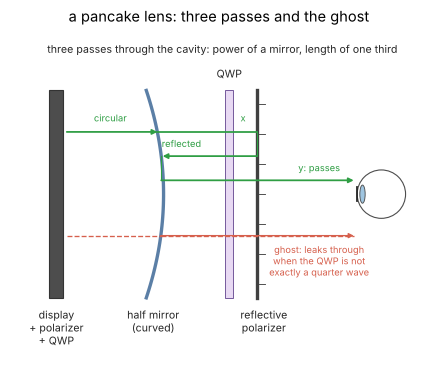

In [2]:
fig, ax = plt.subplots(figsize=(12, 5.5))
with sketch.text_scale(1.2):
    sketch.pancake_lens(ax, title="a pancake lens: three passes and the ghost")
plt.show()

## 1. The fold with ideal parts

The parts, from the display to the eye:

1. the display with a linear polarizer (along $x$) and a quarter wave
   plate at 45°, which makes the light circular,
2. a half mirror (50 % reflection, 50 % transmission), coated on a curved
   lens surface,
3. a quarter wave plate (QWP) at −45°, which turns the circular light into
   linear light along $x$,
4. a **reflective polarizer** (a wire grid or a birefringent multilayer
   film), which reflects $x$ and transmits $y$.

The $x$ light is reflected, passes the QWP again (circular), is reflected
by the half mirror (the handedness flips, because the direction of travel
does), passes the QWP a third time, now along $y$, and leaves through the
reflective polarizer towards the eye. A clean-up polarizer along $y$
behind it absorbs what is left of $x$.

`arvr.pancake_jones()` follows the field in a fixed lab frame: $x$ and
$y$ keep their meaning for both directions of travel, a mirror multiplies
by −1, and a retarder passed backwards has the transposed Jones matrix
(the same matrix for a single plate, reversed order for a stack). The
half mirror's transmission (½) and reflection (½) in power are the
only losses with ideal parts: $\tfrac12\cdot\tfrac12 = 25\,\%$.

In [3]:
QWP_IN = J_WP(np.pi/2, np.pi/4)
ideal = arvr.pancake_jones(J_WP(np.pi/2, -np.pi/4), J_input=QWP_IN)
for k in ("T_signal", "T_direct", "T_five_pass"):
    print("{:12s} {:.4f}".format(k, ideal[k]))
print("Jones vector at the eye:", np.round(ideal["signal"], 4))
wrong = arvr.pancake_jones(J_WP(np.pi/2, +np.pi/4), J_input=QWP_IN)
print("QWP at +45° instead: signal {:.3f}, direct {:.3f}".format(wrong["T_signal"], wrong["T_direct"]))

T_signal     0.2500
T_direct     0.0000
T_five_pass  0.0000
Jones vector at the eye: [ 0.+0.j  -0.-0.5j]
QWP at +45° instead: signal 0.000, direct 0.500


With ideal parts exactly 25 % reaches the eye, linearly polarized along
$y$, and nothing takes the direct or the five-pass path. Turning the
cavity plate to +45° instead swaps the roles: the light passes the
reflective polarizer at once (50 %, the half mirror's transmission) and
none is folded. The pancake is a polarization switch, and every error of
the switch shows up as light on the wrong path.

## 2. The optics of the fold

The folded path passes the gap $d$ between half mirror and reflective
polarizer three times and is reflected once by the curved half mirror,
with the focal length $R/2$ of a mirror. The direct path passes the gap
once and sees no mirror. With the ABCD matrices of
notebook 08 (ABCD matrices), `abcd.mirror()`,
`abcd.free_space()` and `abcd.image()`, a model in air: half mirror of
radius 80 mm (focal length 40 mm), gap 8 mm, the eye 12 mm behind the
reflective polarizer, and the display placed so that the virtual image is
1.5 m away. The transmitting side of the half mirror is taken as a
meniscus without power, and the gap is filled with air.

A conventional single lens of 40 mm focal length needs the display about
39 mm in front of the lens. The pancake puts it a few millimetres in front
of the half mirror: the whole stack from display to reflective polarizer
is the distance below.

In [4]:
R_HM, GAP, EYE_RELIEF, VID = 80.0, 8.0, 12.0, 1500.0


def folded(s):
    """display -> half mirror (s) -> RP (gap) -> HM (gap, reflection) -> RP (gap) -> eye."""
    return abcd.compose(abcd.free_space(s + GAP), abcd.free_space(GAP), abcd.mirror(R_HM),
                        abcd.free_space(GAP), abcd.free_space(EYE_RELIEF))


def direct(s):
    return abcd.compose(abcd.free_space(s + GAP + EYE_RELIEF))


# display distance s for a virtual image VID in front of the eye
s_grid = np.linspace(0.5, 30, 20000)
img = np.array([abcd.image(folded(s), 0.0)[0] for s in s_grid])     # image measured from the eye plane
s_disp = s_grid[np.argmin(np.abs(img + VID))]
efl = -1/folded(s_disp)[1, 0]
print("display {:.2f} mm in front of the half mirror; stack display -> RP {:.1f} mm".format(
    s_disp, s_disp + GAP))
print("effective focal length {:.1f} mm; a single lens of that focal length needs the display "
      "{:.1f} mm away".format(efl, 1/(1/efl - 1/(VID - EYE_RELIEF))))
v_sig = -1/abcd.image(folded(s_disp), 0.0)[0]*1e3           # vergence at the eye in diopters (m^-1)
v_ghost = 1/(s_disp + GAP + EYE_RELIEF)*1e3
print("vergence at the eye: image {:.2f} D, direct ghost {:.1f} D".format(v_sig, v_ghost))
pupil = 4.0
blur = pupil*1e-3*(v_ghost - v_sig)
print("the ghost is a blur of {:.1f} mrad = {:.1f}° for a 4 mm pupil; the eye cannot focus on it "
      "(accommodation range ~ 10 D at best)".format(1e3*blur, np.degrees(blur)))

display 22.95 mm in front of the half mirror; stack display -> RP 30.9 mm
effective focal length 40.0 mm; a single lens of that focal length needs the display 41.1 mm away
vergence at the eye: image 0.67 D, direct ghost 23.3 D
the ghost is a blur of 90.5 mrad = 5.2° for a 4 mm pupil; the eye cannot focus on it (accommodation range ~ 10 D at best)


The pancake puts the display 23 mm in front of the half mirror and the
whole stack from display to reflective polarizer is 31 mm long; a single
lens of the same 40 mm focal length needs the display 41 mm in front of
it, plus the lens. The fold buys about a factor 1.3 to 1.5 in this simple
model; real pancakes go further by giving the half mirror and the lens
surfaces more power and by filling the cavity with glass, and reach total
tracks around 20 mm.

The image arrives at the eye with 0.67 D of divergence (1.5 m), the ghost
with 23 D: it comes straight from the display 43 mm away, unfocused.
Through a 4 mm pupil this is a blur of 5° around every bright object. The
eye cannot accommodate to it, so the ghost is not a second sharp image
but a halo. That makes small ghosts tolerable on bright scenes and
visible on dark ones.

## 3. Real retarders over the spectrum

A quarter wave plate is a quarter wave at one wavelength only. A plate of
thickness $t$ and birefringence $\Delta n(\lambda)$ has the retardance
$\delta = 2\pi\Delta n\,t/\lambda$ (`arvr.aplate_retardance()`). Crystal
quartz, with the Sellmeier fit of Ghosh (`arvr.quartz_indices()`), has
$\Delta n = 0.0092$ at 550 nm, rising towards the blue. Three plates for
550 nm:

- a **zero-order** plate, $t = \lambda/(4\Delta n) \approx 15\,\mu$m
  (in practice two thick plates crossed with this difference),
- a **multi-order** plate, eleven and a quarter waves, about 0.67 mm:
  cheap and robust, but $\delta$ runs eleven times faster with $1/\lambda$,
- **Pancharatnam's achromatic** combination, a half wave plate at 15° and
  a quarter wave plate at 75°, whose errors cancel to first order
  (`arvr.achromatic_qwp()`). Its axes are not those of a single plate,
  and the cavity plate is passed in both directions, so the order of its
  two plates matters: the orientation and the order are found below by
  maximizing the worst image efficiency from 450 to 650 nm.

The display's own quarter wave plate is the same kind of plate. The
reflective polarizer and the clean-up polarizer are ideal here.
Polymer retarder films with reverse dispersion ($\Delta n \propto \lambda$,
so $\delta$ constant) are what better pancakes use; they correspond to
the ideal line.

quartz: Δn(550 nm) = 0.00916; zero-order QWP 15.0 µm, multi-order 676 µm


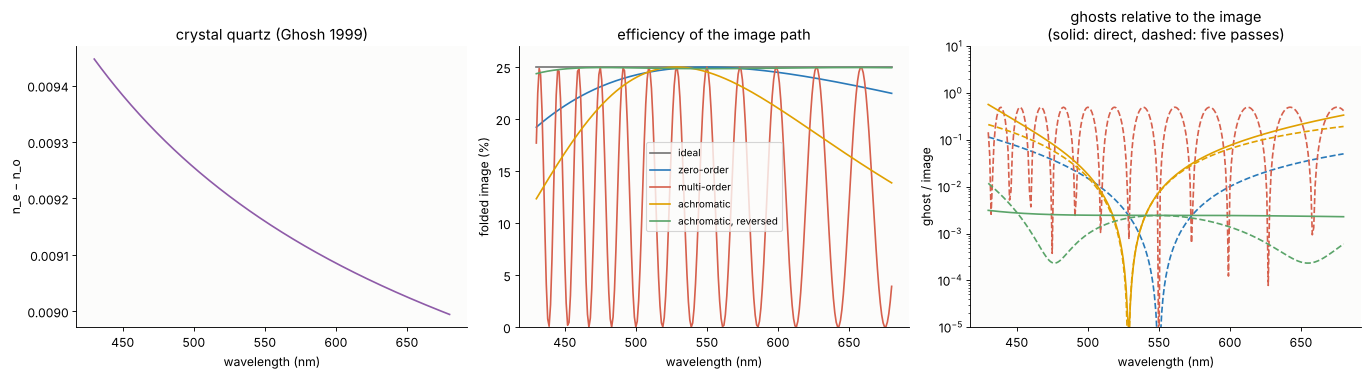

ideal               : cavity plate at -45.00°; 450-650 nm: image 25.0 to 25.0 %, ghost/image max 0.00%, five-pass/image max 0.00%
zero-order          : cavity plate at -45.00°; 450-650 nm: image 21.3 to 25.0 %, ghost/image max 0.00%, five-pass/image max 7.43%
multi-order         : cavity plate at -45.00°; 450-650 nm: image 0.0 to 25.0 %, ghost/image max 0.00%, five-pass/image max 50.00%
achromatic          : cavity plate at -26.50°; 450-650 nm: image 16.5 to 25.0 %, ghost/image max 24.91%, five-pass/image max 14.52%
achromatic, reversed: cavity plate at -88.00°; 450-650 nm: image 24.8 to 25.0 %, ghost/image max 0.28%, five-pass/image max 0.29%


In [5]:
LAM0 = 550.0
lam = np.linspace(430, 680, 251)
n_o, n_e = arvr.quartz_indices(lam)
dn = n_e - n_o
dn0 = np.interp(LAM0, lam, dn)
t_zero = LAM0/(4*dn0)
t_multi = (11 + 0.25)*LAM0/dn0
t_hwp = LAM0/(2*dn0)
print("quartz: Δn(550 nm) = {:.5f}; zero-order QWP {:.1f} µm, multi-order {:.0f} µm".format(
    dn0, t_zero*1e-3, t_multi*1e-3))


def plates(kind, l, dn_l, angle_cavity):
    """Display QWP (input) and cavity QWP of one kind at the wavelength l."""
    if kind == "ideal":
        return J_WP(np.pi/2, np.pi/4), J_WP(np.pi/2, angle_cavity)
    if kind == "zero-order":
        d = 2*np.pi*dn_l*t_zero/l
        return J_WP(d, np.pi/4), J_WP(d, angle_cavity)
    if kind == "multi-order":
        d = 2*np.pi*dn_l*t_multi/l
        return J_WP(d, np.pi/4), J_WP(d, angle_cavity)
    if kind in ("achromatic", "achromatic, reversed"):
        dq, dh = 2*np.pi*dn_l*t_zero/l, 2*np.pi*dn_l*t_hwp/l
        Jc = arvr.achromatic_qwp(dh, dq, angle_cavity)
        return arvr.achromatic_qwp(dh, dq, 0.0), (Jc.T if kind.endswith("reversed") else Jc)
    raise ValueError(kind)


VIS = (lam >= 450) & (lam <= 650)


def best_angle(kind):
    """Orientation of the cavity retarder with the best worst-case image efficiency over 450-650 nm."""
    angs = np.radians(np.arange(-90, 90, 0.5))
    worst = []
    for a in angs:
        worst.append(min(arvr.pancake_jones(plates(kind, l, d_, a)[1], J_input=plates(kind, l, d_, a)[0])["T_signal"]
                         for l, d_ in zip(lam[VIS][::5], dn[VIS][::5])))
    return angs[int(np.argmax(worst))]


kinds = {"ideal": GREY, "zero-order": BLUE, "multi-order": RED, "achromatic": ORANGE,
         "achromatic, reversed": GREEN}
angles = {k: best_angle(k) for k in kinds}
spectra = {}
for k in kinds:
    out = [arvr.pancake_jones(plates(k, l, d_, angles[k])[1], J_input=plates(k, l, d_, angles[k])[0])
           for l, d_ in zip(lam, dn)]
    spectra[k] = (np.array([o["T_signal"] for o in out]), np.array([o["T_direct"] for o in out]),
                  np.array([o["T_five_pass"] for o in out]))
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
axs[0].plot(lam, dn, color=PURPLE)
axs[0].set_xlabel("wavelength (nm)")
axs[0].set_ylabel("n_e − n_o")
axs[0].set_title("crystal quartz (Ghosh 1999)")
for k, c in kinds.items():
    sig, gh, five = spectra[k]
    axs[1].plot(lam, 100*sig, color=c, label=k)
    axs[2].semilogy(lam, np.maximum(gh/sig, 1e-6), color=c, label=k)
    axs[2].semilogy(lam, np.maximum(five/sig, 1e-6), color=c, ls="--")
axs[1].set_xlabel("wavelength (nm)")
axs[1].set_ylabel("folded image (%)")
axs[1].set_ylim(0, 27)
axs[1].set_title("efficiency of the image path")
axs[1].legend(fontsize=9)
axs[2].set_xlabel("wavelength (nm)")
axs[2].set_ylabel("ghost / image")
axs[2].set_ylim(1e-5, 10)
axs[2].set_title("ghosts relative to the image\n(solid: direct, dashed: five passes)")
plt.show()
for k in kinds:
    sig, gh, five = spectra[k]
    vis = VIS
    print("{:20s}: cavity plate at {:6.2f}°; 450-650 nm: image {:.1f} to {:.1f} %, ghost/image max {:.2%}, "
          "five-pass/image max {:.2%}".format(k, np.degrees(angles[k]), 100*sig[vis].min(), 100*sig[vis].max(),
                                             (gh/sig)[vis].max(), (five/sig)[vis].max()))

Quartz has $\Delta n = 0.00916$ at 550 nm, 3 % more in the blue and
2 % less in the red. The results over 450 to 650 nm:

- **Zero-order plates** (15 µm): the image path drops from 25 % to
  21 % at the ends of the spectrum, and the error goes into the five-pass
  ghost (up to 7 % of the image), not the direct one. The reason: the
  display plate and the cavity plate are identical and crossed (+45° and
  −45°), so on the direct path their errors cancel exactly at every
  wavelength, and the light that should be reflected still is. The
  mismatch only appears on the way back, after a reflection has flipped
  the handedness.
- **Multi-order plates** (676 µm, eleven waves): the retardance sweeps
  through many waves over the visible, and the image efficiency
  oscillates between 0 and 25 % every 20 nm. Useless for a display.
- **Pancharatnam's combination** depends on the order of its plates in the
  cavity. In the order of the single-pass design (half wave plate first,
  seen from the display) it is worse than a zero-order plate: 17 % in the
  blue and a direct ghost of up to 25 %. Reversed (quarter wave plate
  first) and turned to −88°, it keeps the image above 24.8 % and both
  ghosts below 0.3 % over 450 to 650 nm. The remaining 0.25 % direct ghost
  is constant: the combination is not a pure linear retarder, so it never
  exactly cancels the display plate.

## 4. The angle of incidence

The eye looks through the pancake at field angles of up to 45° and more.
A plate with its optic axis in its plane (an A-plate) has a retardance
that depends on the angle of incidence and on the azimuth of the plane of
incidence relative to the axis: for incidence in the plane of the axis
the extraordinary index moves towards $n_o$ and the retardance drops, in
the perpendicular plane it rises
(`arvr.aplate_retardance()` evaluates the exact normal wave vector
components of the two eigenwaves). Below, the ghost of the zero-order
and the achromatic quartz pancake over a ±45° field at 550 nm, with the
cavity plate tilted by the field angle (the display plate sees the chief
ray of a pixel, nearly normal, and keeps its design retardance). The
rotation of the eigenpolarizations at oblique incidence and the
reflective polarizer's own angular behaviour are left out; they add to
the ghost.

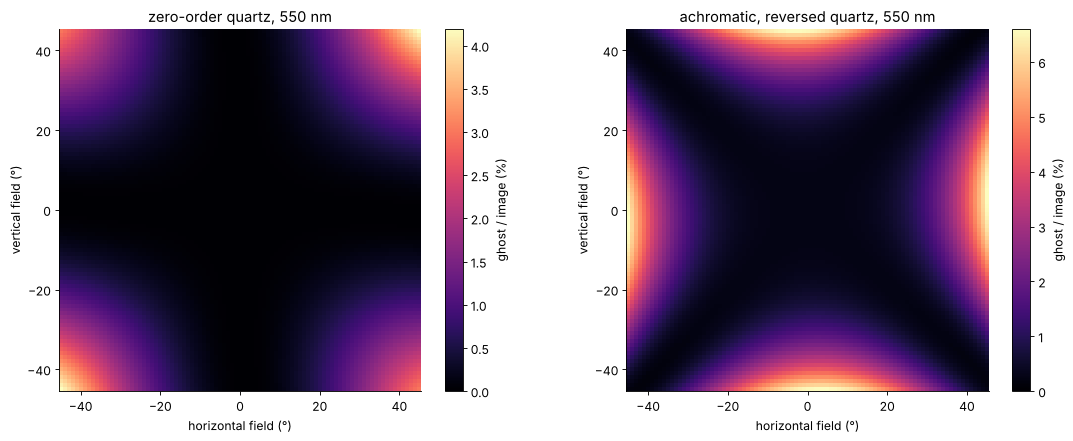

zero-order           : ghost/image at the centre 0.000%, within 20° 0.07% max, at 45° (diagonal) 4.20%
achromatic, reversed : ghost/image at the centre 0.245%, within 20° 0.50% max, at 45° (diagonal) 6.61%


In [6]:
fa = np.radians(np.linspace(-45, 45, 91))
TX, TY = np.meshgrid(fa, fa)
kx, ky = arvr.field_to_k(TX, TY)
s_inc = np.hypot(kx, ky)
psi = np.arctan2(ky, kx)
fig, axs = plt.subplots(1, 2, figsize=(14, 5.4), layout="constrained")
ghost_maps = {}
for ax, kind in zip(axs, ("zero-order", "achromatic, reversed")):
    a_cav = angles[kind]
    G = np.zeros_like(TX)
    for (i, j), _ in np.ndenumerate(G):
        if kind == "zero-order":
            d = arvr.aplate_retardance(t_zero, LAM0, n_o=np.interp(LAM0, lam, n_o), n_e=np.interp(LAM0, lam, n_e),
                                       sin_theta=s_inc[i, j], azimuth=psi[i, j] - a_cav)
            Jc = J_WP(d, a_cav)
            Ji = plates(kind, LAM0, dn0, a_cav)[0]
        else:
            no0, ne0 = np.interp(LAM0, lam, n_o), np.interp(LAM0, lam, n_e)
            dh = arvr.aplate_retardance(t_hwp, LAM0, no0, ne0, s_inc[i, j], psi[i, j] - (a_cav + np.radians(15)))
            dq = arvr.aplate_retardance(t_zero, LAM0, no0, ne0, s_inc[i, j], psi[i, j] - (a_cav + np.radians(75)))
            Jc = (J_WP(dq, a_cav + np.radians(75)) @ J_WP(dh, a_cav + np.radians(15))).T
            Ji = plates(kind, LAM0, dn0, a_cav)[0]
        o = arvr.pancake_jones(Jc, J_input=Ji)
        G[i, j] = o["T_direct"]/o["T_signal"]
    ghost_maps[kind] = G
    im = ax.pcolormesh(np.degrees(fa), np.degrees(fa), 100*G, cmap="magma", shading="auto",
                       vmin=0, vmax=max(1.0, 100*G.max()))
    fig.colorbar(im, ax=ax, label="ghost / image (%)")
    ax.set_xlabel("horizontal field (°)")
    ax.set_ylabel("vertical field (°)")
    ax.set_aspect("equal")
    ax.set_title("{} quartz, 550 nm".format(kind))
plt.show()
for kind, G in ghost_maps.items():
    r = np.degrees(np.hypot(TX, TY))
    print("{:21s}: ghost/image at the centre {:.3%}, within 20° {:.2%} max, at 45° (diagonal) {:.2%}".format(
        kind, G[45, 45], G[r <= 20].max(), G.max()))

For the zero-order plate the ghost stays near zero along the horizontal
and vertical directions and grows along the diagonals. The optic axis of
the cavity plate is at −45°, so a diagonal plane of incidence contains the
axis or is perpendicular to it: there the extraordinary index changes
with the angle and the retardance moves most, with $\sin^2\theta$. In
the horizontal and vertical planes, at 45° to the axis, the changes of
the two contributions nearly cancel. The ghost reaches 4.2 % of the
image in the corners at 45°/45° and stays below 0.1 % within 20°. The
achromatic combination, built from plates at other angles, has its worst
directions on the horizontal and vertical axes and reaches 6.6 %, more
than the simple plate, although it is far better over the spectrum.
Wide field pancakes therefore use retarders whose angular behaviour is
compensated (biaxial films, or C-plates with the axis along the normal),
which this model leaves out.

## 5. The ghost budget

The quarter wave plates are one source of the ghost. The reflective
polarizer is another: if it transmits a fraction $\epsilon^2$ of the
$x$ light it should reflect, that light goes straight to the eye.
The clean-up polarizer stops most of it (it passes $y$ only), but any
retardance error turns some of the direct light into $y$. Below, the
direct ghost against the leak of the reflective polarizer and against the
error of the cavity QWP, with an ideal display plate, and the extinction
of the clean-up polarizer as a second line.

How much ghost is acceptable? It is spread over a large blur (section 2),
so its local contrast against the image is lower than the ratio of the
powers, but on a dark background next to a bright object it is visible
at a per cent. Display makers' targets for pancakes are a ghost of well
below one per cent.

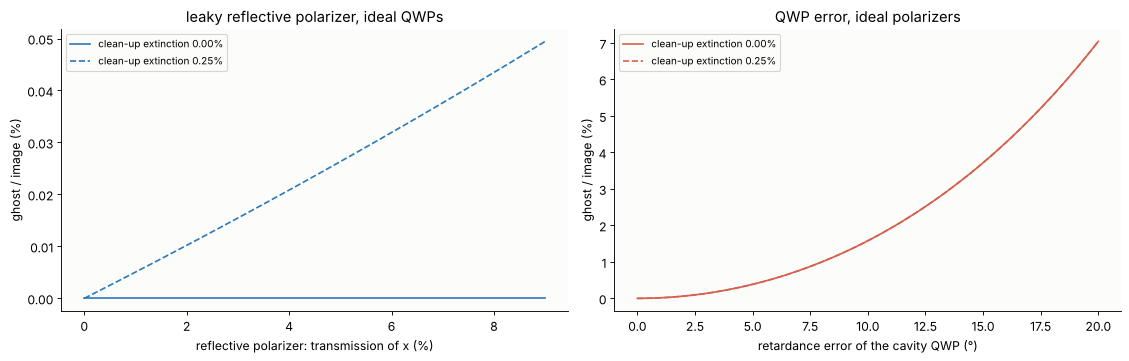

a 1 % ghost needs a cavity QWP within 8.0° of 90° retardance (12 nm at 550 nm)
reflective polarizer with 5 % leak, perfect clean-up: ghost/image 3.78e-32
... and a clean-up polarizer with 0.25 % extinction: ghost/image 0.03%


In [7]:
leaks = np.linspace(0, 0.3, 61)                  # amplitude transmission for x
errs = np.radians(np.linspace(0, 20, 81))        # retardance error of the cavity QWP
fig, axs = plt.subplots(1, 2, figsize=(14, 4.4), layout="constrained")
for ext, ls in ((0.0, "-"), (0.05, "--")):
    g = [arvr.pancake_jones(J_WP(np.pi/2, -np.pi/4), J_input=QWP_IN, leak=L, extinction=ext) for L in leaks]
    axs[0].plot(100*leaks**2, [100*o["T_direct"]/o["T_signal"] for o in g], color=BLUE, ls=ls,
                label="clean-up extinction {:.2%}".format(ext**2))
    g = [arvr.pancake_jones(J_WP(np.pi/2 + e, -np.pi/4), J_input=QWP_IN, extinction=ext) for e in errs]
    axs[1].plot(np.degrees(errs), [100*o["T_direct"]/o["T_signal"] for o in g], color=RED, ls=ls,
                label="clean-up extinction {:.2%}".format(ext**2))
axs[0].set_xlabel("reflective polarizer: transmission of x (%)")
axs[0].set_ylabel("ghost / image (%)")
axs[0].set_title("leaky reflective polarizer, ideal QWPs")
axs[0].legend(fontsize=9)
axs[1].set_xlabel("retardance error of the cavity QWP (°)")
axs[1].set_ylabel("ghost / image (%)")
axs[1].set_title("QWP error, ideal polarizers")
axs[1].legend(fontsize=9)
plt.show()
e1 = np.radians(np.interp(1.0, [100*arvr.pancake_jones(J_WP(np.pi/2 + e, -np.pi/4), J_input=QWP_IN)["T_direct"]
                                 / arvr.pancake_jones(J_WP(np.pi/2 + e, -np.pi/4), J_input=QWP_IN)["T_signal"]
                                 for e in errs], np.degrees(errs)))
print("a 1 % ghost needs a cavity QWP within {:.1f}° of 90° retardance ({:.0f} nm at 550 nm)".format(
    np.degrees(e1), np.degrees(e1)/360*LAM0))
o = arvr.pancake_jones(J_WP(np.pi/2, -np.pi/4), J_input=QWP_IN, leak=np.sqrt(0.05), extinction=0.0)
print("reflective polarizer with 5 % leak, perfect clean-up: ghost/image {:.2e}".format(o["T_direct"]/o["T_signal"]))
o = arvr.pancake_jones(J_WP(np.pi/2, -np.pi/4), J_input=QWP_IN, leak=np.sqrt(0.05), extinction=np.sqrt(0.0025))
print("... and a clean-up polarizer with 0.25 % extinction: ghost/image {:.2%}".format(o["T_direct"]/o["T_signal"]))

The leak of the reflective polarizer goes straight through but is $x$
polarized, so the clean-up polarizer removes it: with a perfect clean-up
polarizer the leak causes no ghost at all, with a realistic 0.25 %
extinction a 5 % leak becomes a 0.03 % ghost. The error of the cavity
quarter wave plate, alone (with a perfect display plate), is the
dangerous part: its direct ghost is $y$ polarized and passes everything.
A 1 % ghost needs the plate within 8° of a quarter wave, 12 nm of
retardance at 550 nm, over the whole spectrum and field. The display's own
plate is the other half of the budget: matched to the cavity plate it
cancels the cavity plate's error on the direct path (section 3).

## Summary

- A pancake lens folds the path three times between a curved half mirror
  and a reflective polarizer; a quarter wave plate between them decides
  whether the light is reflected or transmitted. With ideal parts 25 % of
  the light arrives, and there is no ghost.
- The fold puts a mirror's power into a third of the length: the display
  sits a few millimetres from the optics instead of a focal length away.
  The ghost takes the direct path, without the mirror's power, and
  arrives tens of diopters out of focus.
- The quarter wave plate is a quarter wave at one wavelength and one angle
  only. A multi-order plate ghosts badly over the visible, a zero-order
  plate by a few per cent at the ends of the spectrum, an achromatic
  combination much less; the angle of incidence adds a ghost that grows
  towards the edge of the field.
- The reflective polarizer's leak is caught by the clean-up polarizer;
  their product and the retarders' errors make the ghost budget.

## References

- J. A. LaRussa and A. T. Gill, "The holographic pancake window", Proc.
  SPIE 0162, 120–129 (1978).
- T. L. Wong, Z. Yun, G. Ambur and J. Etter, "Folded optics with
  birefringent reflective polarizers", Proc. SPIE 10335, 103350E (2017).
- J. Xiong, E.-L. Hsiang, Z. He, T. Zhan and S.-T. Wu, "Augmented reality
  and virtual reality displays: emerging technologies and future
  perspectives", Light Sci. Appl. 10, 216 (2021).
- G. Ghosh, "Dispersion-equation coefficients for the refractive index and
  birefringence of calcite and quartz crystals", Opt. Commun. 163, 95–102
  (1999).
- S. Pancharatnam, "Achromatic combinations of birefringent plates",
  Proc. Indian Acad. Sci. A 41, 130–136 (1955).
- P. Yeh and C. Gu, *Optics of Liquid Crystal Displays*, 2nd ed., Wiley
  (2010).

In [8]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 9 s
